In [393]:
import json
import os
from pathlib import Path
from src.audio import load_audio, rms_db
import src.config as config
from src.dataset import get_embeddings, TestDataset, PrecomputedDataset, mashup_collate_fn, test_collate_fn
from src.models import EffNetB0
from src.utils import get_train_stats
from src.metrics import compute_fid
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

In [1]:
# _t = torch.from_numpy(np.load("precomputed/train_v3/00454.npz", mmap_mode="r")["mel"]).unsqueeze(0).unsqueeze(0)
# librosa.display.specshow(data=spec_augment(_t).squeeze(0).squeeze(0).numpy(), sr=SR, hop_length=HOP_LENGTH)
# librosa.display.specshow(
#     librosa.power_to_db(librosa.feature.melspectrogram(y=load_audio("data/messy_mashup/mashups/song0002.wav")), ref=np.max),
#     sr=SR)
# librosa.display.specshow(data=spec_augment(_t).squeeze(0).squeeze(0).cpu().numpy(), cmap="magma")

## Basic exploration

First off, how many files are there in the datasets?

In [230]:
stems = [f for f in Path(config.STEMS_DIR).rglob("*.wav")]
genres = sorted([p for p in Path(config.STEMS_DIR).iterdir()])
noises = sorted([p for p in Path(config.NOISE_DIR).iterdir() if p.is_file()])
test_paths = sorted([f for f in Path(config.TEST_DIR).iterdir() if f.is_file()])

print(f"Stems: {len(stems)}")
print(f"Genres: {len(genres)} ({[p.name for p in genres]})")
print(f"Noises: {len(noises)}")
print(f"Test: {len(test_paths)}")

Stems: 4000
Genres: 10 (['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock'])
Noises: 2000
Test: 3020


Taking a quick look at the audio files themselves:

In [231]:
print(f"Stem: SR={librosa.get_samplerate(stems[0])}, channels={librosa.load(stems[0], mono=False)[0].ndim}")
print(f"Noise: SR={librosa.get_samplerate(noises[0])}, channels={librosa.load(noises[0], mono=False)[0].ndim}")
print(f"Test: SR={librosa.get_samplerate(test_paths[0])}, channels={librosa.load(test_paths[0], mono=False)[0].ndim}")

Stem: SR=44100, channels=2
Noise: SR=44100, channels=1
Test: SR=22050, channels=1


- The GTZAN stems are sampled at 44.1 kHz in stereo.
- The noises are sampled at 44.1 kHz in mono.
- The test mashups are sampled at 22.05 kHz in mono.

So the stems need to be loaded as mono (by averaging across the channels), which `librosa` does by default when loading `.wav`s. Also, I'll resample *all* the audio files to 22050 Hz across the board, just to simplify things - the extra fidelity doesn't really matter for a task like this, and it'll save on disk space and training time.

Breaking down genres further:

In [232]:
songs_by_genre = dict()
for g in genres:
    songs_by_genre[g.name] = sorted([str(d) for d in (Path(config.STEMS_DIR)/g.name).iterdir()])

In [133]:
for g in genres:
    dirs = sorted([p for p in g.iterdir() if p.is_dir()])
    print(f"{g.name}: {len(dirs)} songs")
    for d in dirs:
        files = [f for f in d.iterdir() if f.is_file()]
        if len(files) != 4:
            print(f"WARNING: {d} doesn't contain all 4 stems.")
        for f in files:
            if os.stat(f).st_size < 4096: # Should be larger than 4 KB
                print(f"WARNING: {f} is likely corrupt.")
            if librosa.get_samplerate(f) != 44100:
                print(f"WARNING: {f} has a mismatched sample rate.")

blues: 100 songs
classical: 100 songs
country: 100 songs
disco: 100 songs
hiphop: 100 songs
jazz: 100 songs
metal: 100 songs
pop: 100 songs
reggae: 100 songs
rock: 100 songs


So the song stems are perfectly class-balanced, and there are no missing stems.

What about the noises? ESC-50 includes an `esc50.csv` that contains metadata about the whole dataset. Let's load that into a dataframe.

In [116]:
noise_df = pd.read_csv("data/messy_mashup/ESC-50-master/meta/esc50.csv")
noise_df["category"].value_counts().sort_index(), noise_df["category"].nunique()

(category
 airplane            40
 breathing           40
 brushing_teeth      40
 can_opening         40
 car_horn            40
 cat                 40
 chainsaw            40
 chirping_birds      40
 church_bells        40
 clapping            40
 clock_alarm         40
 clock_tick          40
 coughing            40
 cow                 40
 crackling_fire      40
 crickets            40
 crow                40
 crying_baby         40
 dog                 40
 door_wood_creaks    40
 door_wood_knock     40
 drinking_sipping    40
 engine              40
 fireworks           40
 footsteps           40
 frog                40
 glass_breaking      40
 hand_saw            40
 helicopter          40
 hen                 40
 insects             40
 keyboard_typing     40
 laughing            40
 mouse_click         40
 pig                 40
 pouring_water       40
 rain                40
 rooster             40
 sea_waves           40
 sheep               40
 siren               40
 sneez

So the noises are also class-balanced, with 40 samples each for 50 unique classes.

## Audio duration

In [181]:
test_ids = [f.name.split(".")[0] for f in test_paths]
df = pd.DataFrame(zip(test_ids, test_paths), columns=["id", "path"])
df["duration"] = df["path"].apply(lambda p: librosa.get_duration(path=p, sr=config.SR))
df[["duration"]].describe()

,duration
count,3020.000000
mean,28.653240
std,3.773619
min,6.060408
25%,29.628662
50%,29.953741
75%,30.013333
max,30.579229


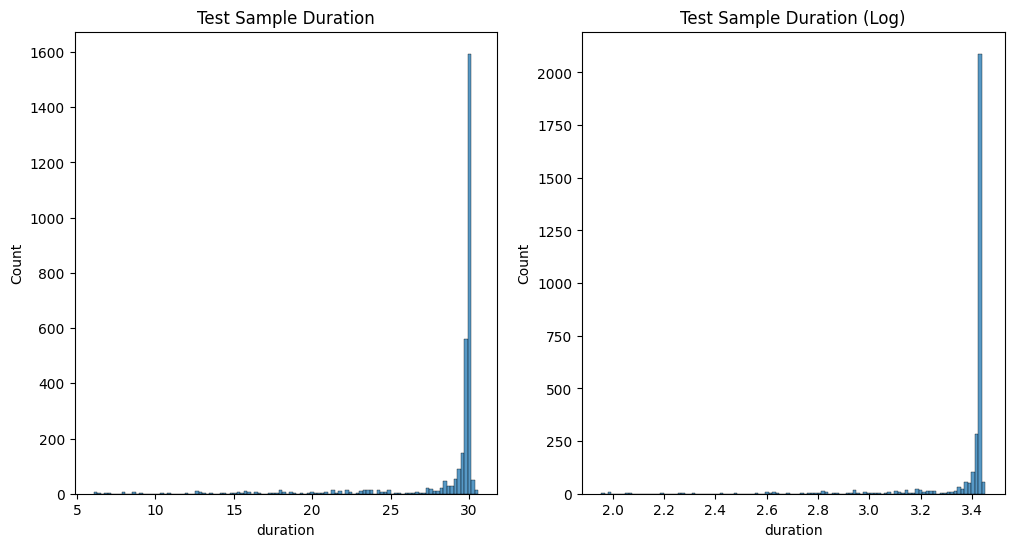

In [200]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
sns.histplot(data=df["duration"], ax=ax[0])
sns.histplot(data=np.log1p(df["duration"]), ax=ax[1])
ax[0].set_title("Test Sample Duration")
ax[1].set_title("Test Sample Duration (Log)")
plt.show()

So the test samples have varying durations, although the median duration is roughly 30s.

In [209]:
stem_durations = [librosa.get_duration(path=f, sr=config.SR) for f in stems]
pd.Series(stem_durations).describe()

count    4000.000000
mean       30.024047
std         0.080883
min        29.931973
25%        30.000181
50%        30.013333
75%        30.013333
max        30.648889
dtype: float64

The stems are all almost exactly 30s long.

In [213]:
noise_durations = [librosa.get_duration(path=f, sr=config.SR) for f in noises]
pd.Series(noise_durations).describe()

count    2000.0
mean        5.0
std         0.0
min         5.0
25%         5.0
50%         5.0
75%         5.0
max         5.0
dtype: float64

The noises are all exactly 5s long.

My takeaway from this is that I need to be careful about what length I pick.

## Audio loudness

In [359]:
noise_rmses = [rms_db(load_audio(path=f, sr=config.SR)) for f in noises]

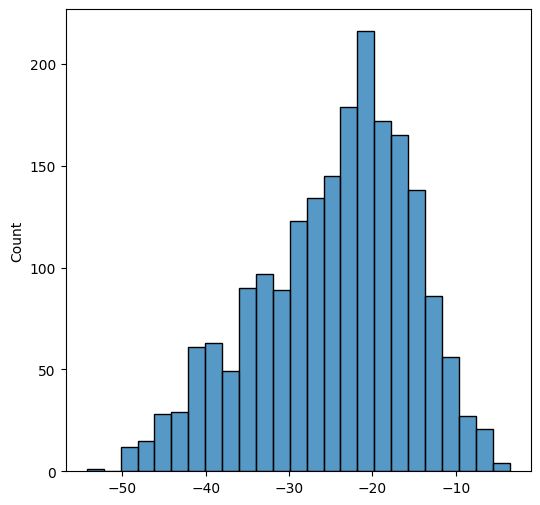

In [362]:
plt.figure(figsize=(6,6))
sns.histplot(noise_rmses)
plt.show()

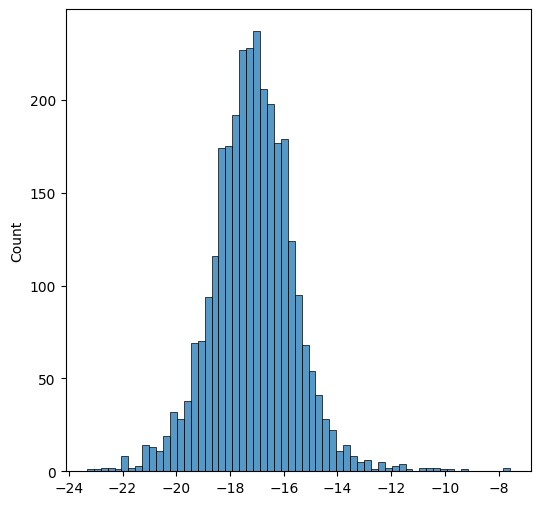

In [363]:
test_rmses = [rms_db(load_audio(path=f, sr=config.SR)) for f in test_paths]
plt.figure(figsize=(6,6))
sns.histplot(test_rmses)
plt.show()

In [397]:
rows = []
for p in stems:
    s = str(p).split("/")
    genre = s[3]
    song = s[4]
    stem = s[5].split(".")[0]
    rms = rms_db(load_audio(path=p, sr=config.SR)[0])
    rows.append((genre, song, stem, rms))

df_stems = pd.DataFrame(rows, columns=["genre", "song", "stem", "rms_db"])
len(df_stems)

4000

In [398]:
df_stems

,genre,song,stem,rms_db
0,rock,rock.00085,bass,-80.000000
1,rock,rock.00085,drums,-80.000000
2,rock,rock.00085,other,-55.143341
3,rock,rock.00085,vocals,-38.598370
4,rock,rock.00041,bass,-71.197174
...,...,...,...,...
3995,reggae,reggae.00089,vocals,-60.672974
3996,reggae,reggae.00020,bass,-22.022886
3997,reggae,reggae.00020,drums,-43.575943
3998,reggae,reggae.00020,other,-52.035248


In [449]:
df_songs = df_stems.groupby(by=["song"], as_index=False)["rms_db"].agg(np.mean)
df_songs["genre"] = df_songs["song"].apply(lambda x: str.split(x, ".")[0])
df_songs

,song,rms_db,genre
0,blues.00000,-54.572670,blues
1,blues.00001,-73.071915,blues
2,blues.00002,-44.177292,blues
3,blues.00003,-58.835979,blues
4,blues.00004,-68.127724,blues
...,...,...,...
995,rock.00095,-40.580471,rock
996,rock.00096,-41.729885,rock
997,rock.00097,-43.915672,rock
998,rock.00098,-50.883232,rock


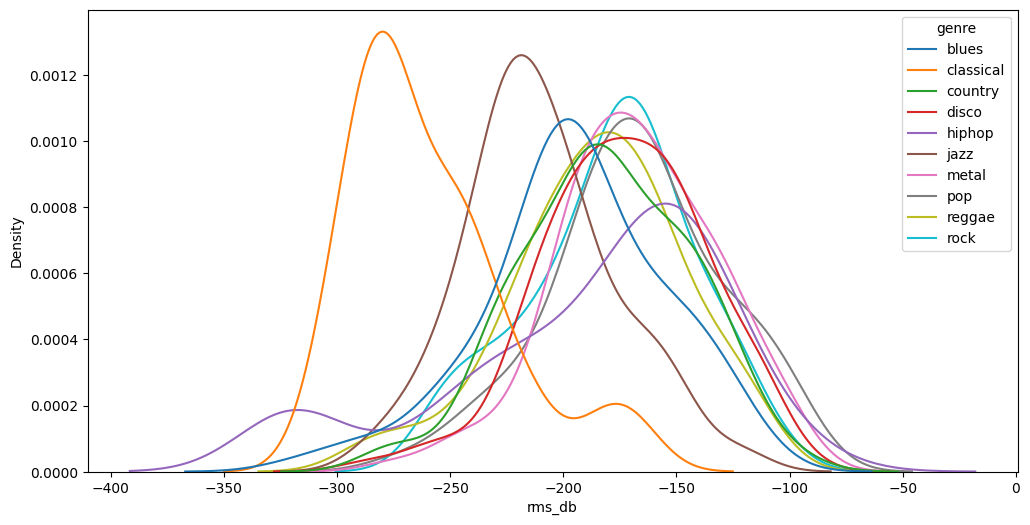

In [452]:
bleh = df_stems.groupby(by=["genre", "song"], as_index=False)["rms_db"].agg(np.sum)
plt.figure(figsize=(12,6))
sns.kdeplot(bleh, x="rms_db", hue="genre")
plt.show()

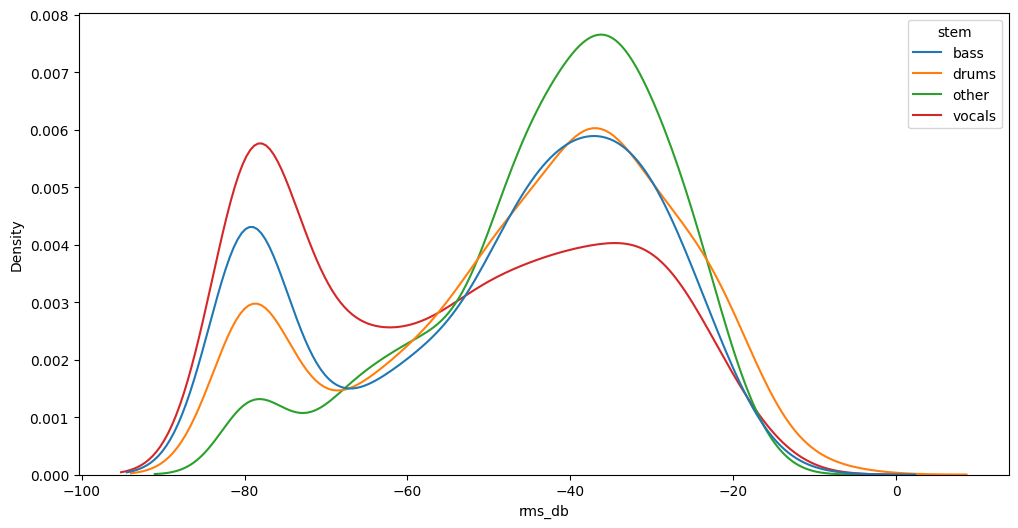

In [457]:
plt.figure(figsize=(12,6))
sns.kdeplot(df_stems, x="rms_db", hue="stem")
plt.show()

### Features

In [220]:
def get_features(path, sr=config.SR, n_mels=config.N_MELS, n_fft=config.N_FFT, hop_length=config.HOP_LENGTH):
    y = load_audio(path, sr=sr)
    duration = len(y)/sr
    rmsdb = rms_db(y)
    zcr = librosa.feature.zero_crossing_rate(y=y, hop_length=hop_length)[0].mean()
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length)[0].mean()
    flatness = librosa.feature.spectral_flatness(y=y, n_fft=n_fft, hop_length=hop_length)[0].mean()
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, roll_percent=0.85)[0].mean()
    return dict(duration=duration, rms_db=rmsdb, zcr=zcr, centroid=centroid, flatness=flatness, rolloff=rolloff)

In [221]:
features = [get_features(f) for f in test_paths]

In [224]:
ft_df = pd.DataFrame.from_dict(features)
ft_df.describe()

,duration,rms_db,zcr,centroid,flatness,rolloff
count,3020.000000,3020.000000,3020.000000,3020.000000,3020.000000,3020.000000
mean,28.653240,-17.146095,0.106069,2288.680010,0.022167,4757.699028
std,3.773619,1.555617,0.038342,586.605961,0.016364,1238.528472
min,6.060408,-23.330507,0.007506,433.976796,0.000150,712.460915
25%,29.628662,-18.071653,0.079992,1901.672551,0.010532,3934.649275
50%,29.953741,-17.152581,0.103493,2272.557383,0.018120,4776.839060
75%,30.013333,-16.193314,0.128773,2663.163209,0.029710,5574.531133
max,30.579229,-7.595422,0.304043,4472.006211,0.127426,8248.715628


## Analyzing my synthetic datasets

### Class balance
First, I want to check whether my synthetic training and validation datasets are at least roughly class-balanced.

In [329]:
with open("precomputed/train_v4_list.txt", "r") as f:
    train_paths = [l.strip() for l in f if l.strip()]

train_genres = []
train_songs = []
for p in train_paths:
    npz = np.load(p, mmap_mode="r")
    meta = json.loads(str(npz["meta"]))
    train_genres.append(meta["genre"])
    train_songs.append(meta["songs"])

df_train = pd.DataFrame([train_paths, train_genres, train_songs]).T
df_train.columns = ["path", "genre", "songs"]
print(df_train.shape)
print(df_train["genre"].value_counts())

(10000, 3)
genre
blues        1060
rock         1022
disco        1013
reggae       1007
pop          1005
classical    1002
metal        1002
country       998
jazz          963
hiphop        928
Name: count, dtype: int64


In [331]:
with open("precomputed/val_v4_list.txt", "r") as f:
    val_paths = [l.strip() for l in f if l.strip()]

val_genres = []
val_songs = []
for p in val_paths:
    npz = np.load(p, mmap_mode="r")
    meta = json.loads(str(npz["meta"]))
    val_genres.append(meta["genre"])
    val_songs.append(meta["songs"])

df_val = pd.DataFrame([val_paths, val_genres, val_songs]).T
df_val.columns = ["path", "genre", "songs"]
print(df_val.shape)
print(df_val["genre"].value_counts())

(2000, 3)
genre
pop          217
blues        216
classical    209
reggae       206
disco        197
jazz         194
rock         194
hiphop       190
metal        189
country      188
Name: count, dtype: int64


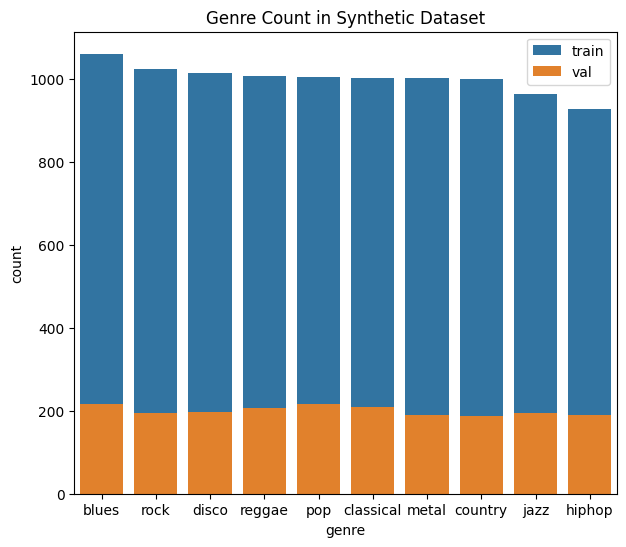

In [349]:
plt.figure(figsize=(7,6))
sns.barplot(df_train["genre"].value_counts(), label="train")
sns.barplot(df_val["genre"].value_counts(), label="val")
plt.legend()
plt.title("Genre Count in Synthetic Dataset")
plt.show()

That's close enough for me.

### Comparing synth and test distributions

In [458]:
mean, std = get_train_stats(config.TRAIN_STATS_PATH)
test_files = sorted([f for f in Path(config.TEST_DIR).iterdir() if f.is_file()])

test_set = TestDataset(test_files, mean=mean, std=std)
train_set = PrecomputedDataset("precomputed/train_v4_list.txt", mean=mean, std=std)

effnet_finetuned = EffNetB0(num_classes=10, pretrained=False, freeze_backbone=True)
ckpt = torch.load(Path(config.CHECKPOINTS_DIR) / "effnetb0.ckpt", map_location="cpu", weights_only=False)
effnet_finetuned.load_state_dict(ckpt["model_state"])

test_loader = DataLoader(
    dataset=test_set,
    batch_size=16,
    shuffle=False,
    num_workers=8,
    pin_memory=False,
    collate_fn=test_collate_fn
)

train_loader = DataLoader(
    dataset=train_set,
    batch_size=16,
    shuffle=False,
    num_workers=8,
    pin_memory=False,
    collate_fn=mashup_collate_fn,
)

test_embeddings = get_embeddings(model=effnet_finetuned, loader=test_loader)
train_embeddings = get_embeddings(model=effnet_finetuned, loader=train_loader)

print(test_embeddings.shape, train_embeddings.shape)
print(compute_fid(train_embeddings, test_embeddings))

(3020, 1280) (10000, 1280)
12.820257711172015


In [459]:
np.savez("precomputed/embeddings.npz", test=test_embeddings, train=train_embeddings)

In [ ]:
import random

rng = random.Random()

rng.choices(train_embeddings, k=2000)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 13020 samples in 0.005s...
[t-SNE] Computed neighbors for 13020 samples in 2.140s...
[t-SNE] Computed conditional probabilities for sample 1000 / 13020
[t-SNE] Computed conditional probabilities for sample 2000 / 13020
[t-SNE] Computed conditional probabilities for sample 3000 / 13020
[t-SNE] Computed conditional probabilities for sample 4000 / 13020
[t-SNE] Computed conditional probabilities for sample 5000 / 13020
[t-SNE] Computed conditional probabilities for sample 6000 / 13020
[t-SNE] Computed conditional probabilities for sample 7000 / 13020
[t-SNE] Computed conditional probabilities for sample 8000 / 13020
[t-SNE] Computed conditional probabilities for sample 9000 / 13020
[t-SNE] Computed conditional probabilities for sample 10000 / 13020
[t-SNE] Computed conditional probabilities for sample 11000 / 13020
[t-SNE] Computed conditional probabilities for sample 12000 / 13020
[t-SNE] Computed conditional probabilities for sam

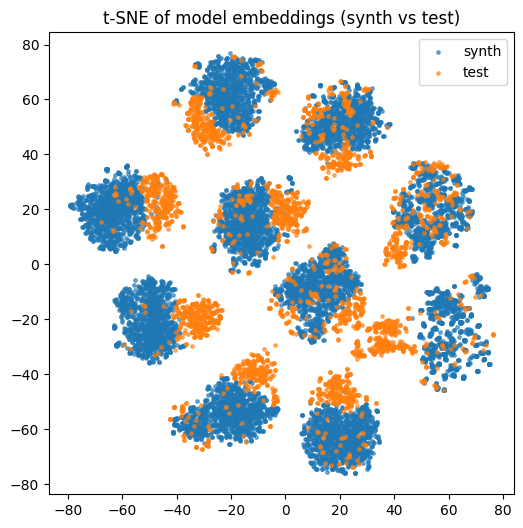

In [482]:
from sklearn.manifold import TSNE

e = rng.choices(train_embeddings, k=3020)
Z = np.concatenate([train_embeddings, test_embeddings], axis=0)
labels = np.array(['synth']*len(train_embeddings) + ['test']*len(test_embeddings))
z2 = TSNE(n_components=2, perplexity=30, random_state=0, verbose=10).fit_transform(Z)
plt.figure(figsize=(6,6))
plt.scatter(z2[labels=='synth',0], z2[labels=='synth',1], s=6, alpha=0.6, label='synth')
plt.scatter(z2[labels=='test',0], z2[labels=='test',1], s=6, alpha=0.6, label='test')
plt.legend()
plt.title("t-SNE of model embeddings (synth vs test)")
plt.show()

In [486]:
plt.figure(figsize=(6,6))
plt.scatter(z2[labels=='synth',0], z2[labels=='synth',1], s=6, alpha=0.6, label='synth')
plt.scatter(z2[labels=='test',0], z2[labels=='test',1], s=6, alpha=0.6, label='test')
plt.legend()
plt.title("t-SNE of model embeddings (synth vs test)")
plt.show()

IndexError: boolean index did not match indexed array along axis 0; size of axis is 10000 but size of corresponding boolean axis is 13020

<Figure size 600x600 with 0 Axes>

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 10000 samples in 0.006s...
[t-SNE] Computed neighbors for 10000 samples in 1.375s...
[t-SNE] Computed conditional probabilities for sample 1000 / 10000
[t-SNE] Computed conditional probabilities for sample 2000 / 10000
[t-SNE] Computed conditional probabilities for sample 3000 / 10000
[t-SNE] Computed conditional probabilities for sample 4000 / 10000
[t-SNE] Computed conditional probabilities for sample 5000 / 10000
[t-SNE] Computed conditional probabilities for sample 6000 / 10000
[t-SNE] Computed conditional probabilities for sample 7000 / 10000
[t-SNE] Computed conditional probabilities for sample 8000 / 10000
[t-SNE] Computed conditional probabilities for sample 9000 / 10000
[t-SNE] Computed conditional probabilities for sample 10000 / 10000
[t-SNE] Mean sigma: 1.327268
[t-SNE] Computed conditional probabilities in 0.319s
[t-SNE] Iteration 50: error = 80.7803116, gradient norm = 0.0297515 (50 iterations in 1.068s)
[t-SNE] It

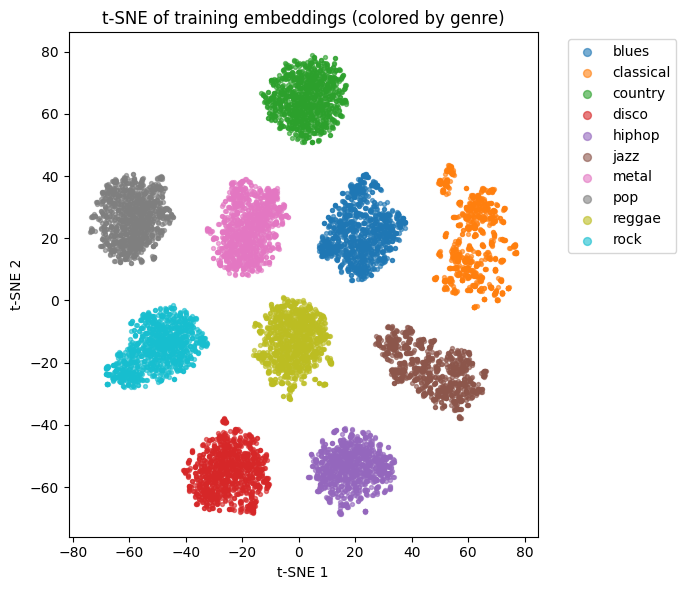

In [ ]:
tsne = TSNE(n_components=2, perplexity=30, random_state=0, verbose=10)
z2 = tsne.fit_transform(train_embeddings)
plt.figure(figsize=(7,6))

lbl = df_train["genre"].to_numpy()
for g in config.GENRES:
    idx = lbl == g
    plt.scatter(z2[idx, 0], z2[idx, 1], s=8, alpha=0.6, label=g)
plt.legend(markerscale=2, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.title("t-SNE of training embeddings (colored by genre)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib

matplotlib.rcParams['axes.prop_cycle'] = matplotlib.cycler(color=["r", "k", "c"]) 

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 13020 samples in 0.004s...
[t-SNE] Computed neighbors for 13020 samples in 2.140s...
[t-SNE] Computed conditional probabilities for sample 1000 / 13020
[t-SNE] Computed conditional probabilities for sample 2000 / 13020
[t-SNE] Computed conditional probabilities for sample 3000 / 13020
[t-SNE] Computed conditional probabilities for sample 4000 / 13020
[t-SNE] Computed conditional probabilities for sample 5000 / 13020
[t-SNE] Computed conditional probabilities for sample 6000 / 13020
[t-SNE] Computed conditional probabilities for sample 7000 / 13020
[t-SNE] Computed conditional probabilities for sample 8000 / 13020
[t-SNE] Computed conditional probabilities for sample 9000 / 13020
[t-SNE] Computed conditional probabilities for sample 10000 / 13020
[t-SNE] Computed conditional probabilities for sample 11000 / 13020
[t-SNE] Computed conditional probabilities for sample 12000 / 13020
[t-SNE] Computed conditional probabilities for sam

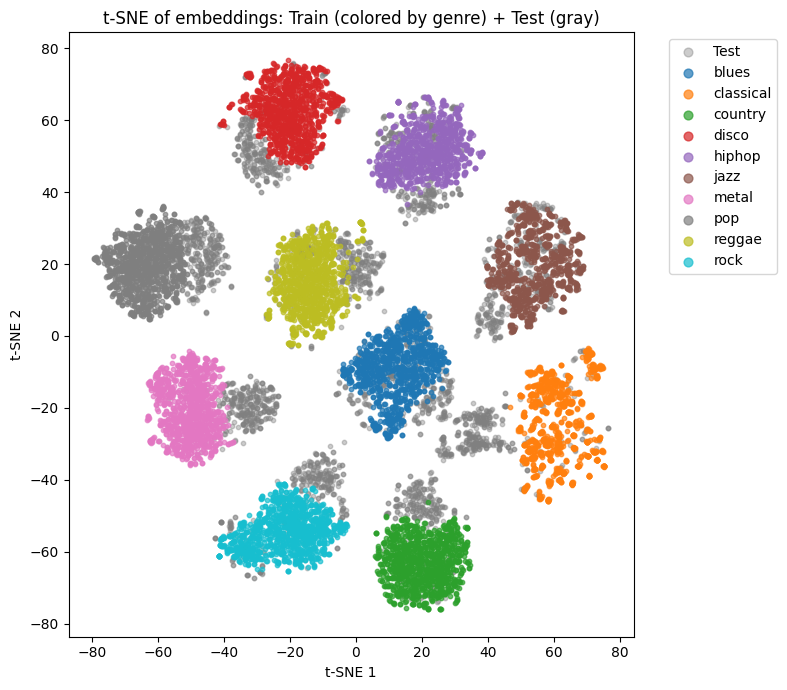

In [481]:
labels = np.array(['synth']*len(e) + ['test']*len(test_embeddings))
Z_all = np.vstack([train_embeddings, test_embeddings])
Z_2d = TSNE(n_components=2, perplexity=30, random_state=0, verbose=10).fit_transform(Z_all)

# Split back
Z_train_2d = Z_2d[:len(train_embeddings)]
Z_test_2d  = Z_2d[len(train_embeddings):]

plt.figure(figsize=(8,7))

# Plot test first (background)
plt.scatter(Z_test_2d[:, 0], Z_test_2d[:, 1], s=10,  alpha=0.4, color="gray", label="Test")

# Plot train per genre
for g in config.GENRES:
    idx = lbl == g
    plt.scatter(Z_train_2d[idx, 0], Z_train_2d[idx, 1], s=10, alpha=0.7, label=g)

plt.legend(markerscale=2, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.title("t-SNE of embeddings: Train (colored by genre) + Test (gray)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.tight_layout()
plt.show()